# 공공데이터를 활용한 미세먼지 농도 예측 프로젝트
## 단계2. 모델링(머신러닝)

## 0.프로젝트 소개

### (1) 수행 목표
- 미세먼지 농도를 예측하는 머신러닝 모델을 만드세요.

#### 우리가 풀어야 하는 문제는 무엇인가요?
* 서울 지역의 미세먼지 데이터와 날씨 데이터를 활용하여,
미세먼지 예측에 관련 있는 데이터 항목으로 데이터를 구성, 전처리 하여
미세먼지 농도를 예측하는 머신러닝 모델 구현


### (2) 데이터 소개

#### 1) 기본 데이터

* 학습 데이터
    * air_2021.csv : 2021년 미세먼지 데이터
    * weather_2021.csv : 2021년 날씨 데이터
* 테스트 데이터
    * air_2022.csv : 2022년 미세먼지 데이터
    * weather_2022.csv : 2022년 날씨 데이터

#### 2) 데이터셋의 변수 소개(weather_2021)

* 증기압: 증기가 고체 또는 액체와 동적 평형 상태에 있을 때 증기의 압력 (증기가 되려는 힘)
* 이슬점 온도: 불포화 상태의 공기가 냉각될 때, 포화 상태에 도달하여 수증기의 응결이 시작되는 온도
* 일조: 일정한 물체나 땅의 겉면에 태양 광선이 비치는 시간 (1시간 중 비율)
* 일사(량): 태양으로부터 오는 태양 복사 에너지가 지표에 닿는 양 (면적당 에너지 량)
* 전운량: 하늘을 육안으로 관측하여 전부 구름일 때 10, 구름이 덮고 있는 하늘의 비율에 따라 0~10
* 중하층운량: 중층과 하층에 있는 구름의 분포량(중하층 구름이 날씨에 영향 주므로 따로 표기)
* 운형(운형약어): 구름의 종류. 약어 코드로 기재됨
* 최저운고: 가장 낮은 구름의 높이
* 현상번호(국내식): 비, 소낙비, 싸락눈, 눈보라 등의 기상현상을 나타낸 코드번호
* 지면온도: 지면 0cm 온도
* 지중온도: 땅 속 온도변수1

#### 2) 라이브러리 로딩

In [1]:
# 필요한 라이브러리 설치 및 임포트

import pandas as pd

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor as DTR
from sklearn.ensemble import RandomForestRegressor as RFR
from sklearn.ensemble import GradientBoostingRegressor as GBR
from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import r2_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import recall_score as recall
import joblib

# [Step 3] 머신러닝 모델링 

#### **<span style="color:blue">[3-1] 학습 및 테스트 데이터 로딩</span>**

In [2]:
import pandas as pd

# 데이터 로딩
train_x = pd.read_csv('train_x.csv', index_col=0)
train_y = pd.read_csv('train_y.csv', index_col=0)
test_x = pd.read_csv('test_x.csv', index_col=0)
test_y = pd.read_csv('test_y.csv', index_col=0)

# --- 수정 포인트: PM 관련 컬럼 제외 ---
# 컬럼명에 'PM'이 포함된 모든 열을 찾아 드롭합니다.
pm_cols = [col for col in train_x.columns if 'PM' in col]
train_x = train_x.drop(columns=pm_cols)
test_x = test_x.drop(columns=pm_cols)

print(f"제거된 컬럼: {pm_cols}")
print(f"남은 학습 변수 개수: {train_x.shape[1]}")
display(train_x.head(3))

제거된 컬럼: ['PM10', 'PM25', 'PM10_lag24', 'PM10_lag1']
남은 학습 변수 개수: 26


,SO2,CO,O3,NO2,기온(°C),강수량(mm),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),...,3시간신적설(cm),전운량(10분위),중하층운량(10분위),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),hour
time,,,,,,,,,,,,,,,,,,,,,
2021-10-03 00:00:00,0.003,0.7,0.007,0.038,19.5,0.0,0.7,360.0,86,19.4,...,0.0,0.0,0,1404,18.2,22.4,22.3,22.7,23.0,0
2021-10-03 01:00:00,0.004,0.7,0.006,0.038,19.1,0.0,0.0,0.0,89,19.6,...,0.0,0.0,0,1249,17.8,22.1,22.1,22.6,22.9,1
2021-10-03 02:00:00,0.003,0.7,0.004,0.041,18.7,0.0,1.0,50.0,91,19.5,...,0.0,0.0,0,700,17.7,21.9,21.9,22.4,22.9,2


---

#### **<span style="color:blue">[3-2] 모델링 : 선형 회귀</span>**

* 머신 모델을 선정하여 아래에 적절한 코드를 작성해주세요.

✅ 학습에 사용된 변수 (26개): ['10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)', '3시간신적설(cm)', '5cm 지중온도(°C)', 'CO', 'NO2', 'O3', 'SO2', 'hour', '강수량(mm)', '기온(°C)', '습도(%)', '시정(10m)', '이슬점온도(°C)', '일사(MJ/m2)', '일조(hr)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)', '증기압(hPa)', '지면온도(°C)', '풍속(m/s)', '풍향(16방위)', '해면기압(hPa)', '현지기압(hPa)']


,Model,R2,MAE,RMSE
1,SVR,0.642489,9.310177,14.168978
4,Random Forest,0.591861,10.134082,15.139029
3,XGBoost,0.586849,10.489007,15.231694
0,Linear Regression,0.409533,12.971278,18.209229
2,Gradient Boosting,0.094582,12.212526,22.548541


C:\Users\5174k\AppData\Local\Temp\ipykernel_41568\106880013.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='R2', y='Model', data=df_results, palette='coolwarm')


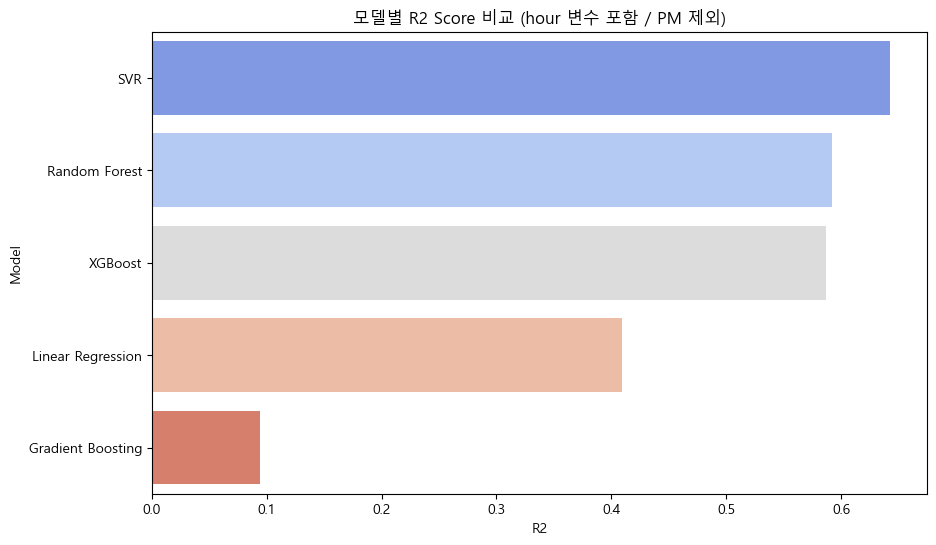

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import platform

# 1. 데이터 로드
train_x = pd.read_csv('train_x.csv')
train_y = pd.read_csv('train_y.csv')
test_x = pd.read_csv('test_x.csv')
test_y = pd.read_csv('test_y.csv')

# 2. 전처리: hour 변수 복구 및 PM 제거
def preprocess_with_hour(df):
    # 'time' 컬럼을 datetime 객체로 변환
    if 'time' in df.columns:
        df['time'] = pd.to_datetime(df['time'])
        # 만약 'hour' 컬럼이 없다면 생성
        if 'hour' not in df.columns:
            df['hour'] = df['time'].dt.hour
        # 'time' 컬럼은 이제 학습에서 제외
        df = df.drop(columns=['time'])
    
    # PM 관련 컬럼 모두 제거
    pm_cols = [col for col in df.columns if 'PM' in col]
    df = df.drop(columns=pm_cols)
    return df

train_x_final = preprocess_with_hour(train_x)
test_x_final = preprocess_with_hour(test_x)

# y값 정리 ('time' 제거)
if 'time' in train_y.columns:
    train_y = train_y.drop(columns=['time'])
if 'time' in test_y.columns:
    test_y = test_y.drop(columns=['time'])

# 두 데이터셋의 컬럼 순서와 구성을 완벽히 맞춤# 두 데이터셋의 컬럼 순서와 구성을 완벽히 맞춤 (최신 문법으로 수정)
common_cols = sorted(list(set(train_x_final.columns) & set(test_x_final.columns)))
train_x_final = train_x_final[common_cols].ffill().bfill()
test_x_final = test_x_final[common_cols].ffill().bfill()

# 끝에 있던 'ㅌ' 오타 제거 완료!
print(f"✅ 학습에 사용된 변수 ({len(common_cols)}개): {common_cols}")


# 3. 데이터 스케일링
scaler = StandardScaler()
train_x_scaled = scaler.fit_transform(train_x_final)
test_x_scaled = scaler.transform(test_x_final)

# 4. 모델 정의
models = {
    "Linear Regression": LinearRegression(),
    "SVR": SVR(kernel='rbf', C=10, gamma=0.1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

# 5. 학습 및 평가
results = []
for name, model in models.items():
    model.fit(train_x_scaled, train_y.values.ravel())
    pred_y = model.predict(test_x_scaled)
    
    r2 = r2_score(test_y, pred_y)
    mae = mean_absolute_error(test_y, pred_y)
    rmse = np.sqrt(mean_squared_error(test_y, pred_y))
    
    results.append({"Model": name, "R2": r2, "MAE": mae, "RMSE": rmse})

# 6. 결과 출력 및 시각화
df_results = pd.DataFrame(results).sort_values(by='R2', ascending=False)
display(df_results)

# 한글 설정
if platform.system() == 'Darwin': plt.rc('font', family='AppleGothic')
elif platform.system() == 'Windows': plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(10, 6))
sns.barplot(x='R2', y='Model', data=df_results, palette='coolwarm')
plt.title('모델별 R2 Score 비교 (hour 변수 포함 / PM 제외)')
plt.savefig('is_real_GB.png')
plt.show()

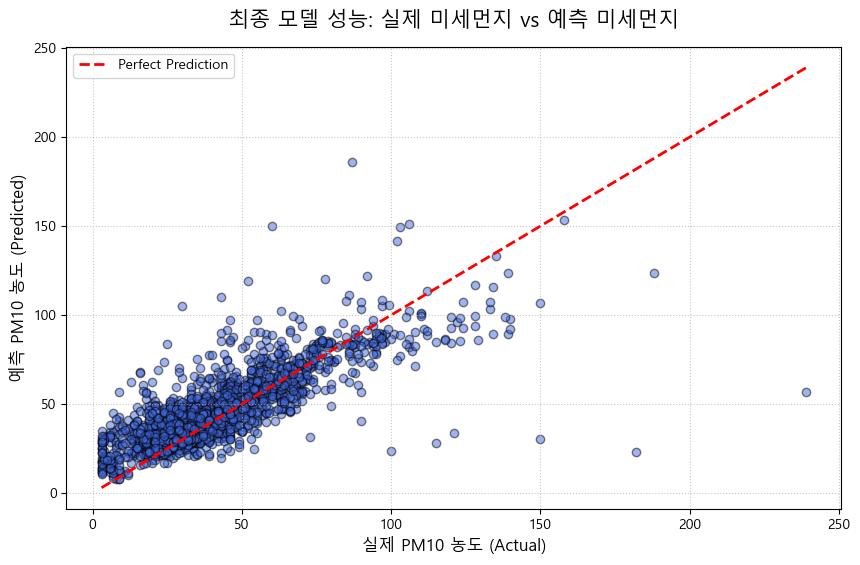

In [ ]:
import matplotlib.pyplot as plt

# 혹시 모를 한글 폰트 깨짐 방지 (Windows 맑은 고딕 기준)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(10, 6))

# 산점도: 실제값 vs 예측값
plt.scatter(test_y, pred_y, alpha=0.5, color='royalblue', edgecolor='k')

# 정답(y=x) 기준선 긋기 (빨간 점선)
# # 정답(y=x) 기준선 긋기 (빨간 점선)
max_val = max(float(test_y.values.max()), float(pred_y.max()))
min_val = min(float(test_y.values.min()), float(pred_y.min()))

plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

# 그래프 꾸미기
plt.title(' 최종 모델 성능: 실제 미세먼지 vs 예측 미세먼지 ', fontsize=15, pad=15)
plt.xlabel('실제 PM10 농도 (Actual)', fontsize=12)
plt.ylabel('예측 PM10 농도 (Predicted)', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

# 형님이 원하신 이미지 파일로 저장! (고화질 dpi=300)
plt.savefig('actual_vs_predicted_fig.png', dpi=300, bbox_inches='tight')

# 화면에 출력
plt.show()


🚀 [이상치 포함 전체 데이터] PCA 압축 비율별 SVR 성능 테스트 시작...

[     80%      ] 사용된 변수: 11개  👉  Test R2 Score: 0.5911
[     85%      ] 사용된 변수: 13개  👉  Test R2 Score: 0.5873
[     90%      ] 사용된 변수: 17개  👉  Test R2 Score: 0.6025
[     95%      ] 사용된 변수: 21개  👉  Test R2 Score: 0.6322
[     97%      ] 사용된 변수: 24개  👉  Test R2 Score: 0.6829
[     99%      ] 사용된 변수: 29개  👉  Test R2 Score: 0.6859
[   원본(100%)   ] 사용된 변수: 41개  👉  Test R2 Score: 0.6807


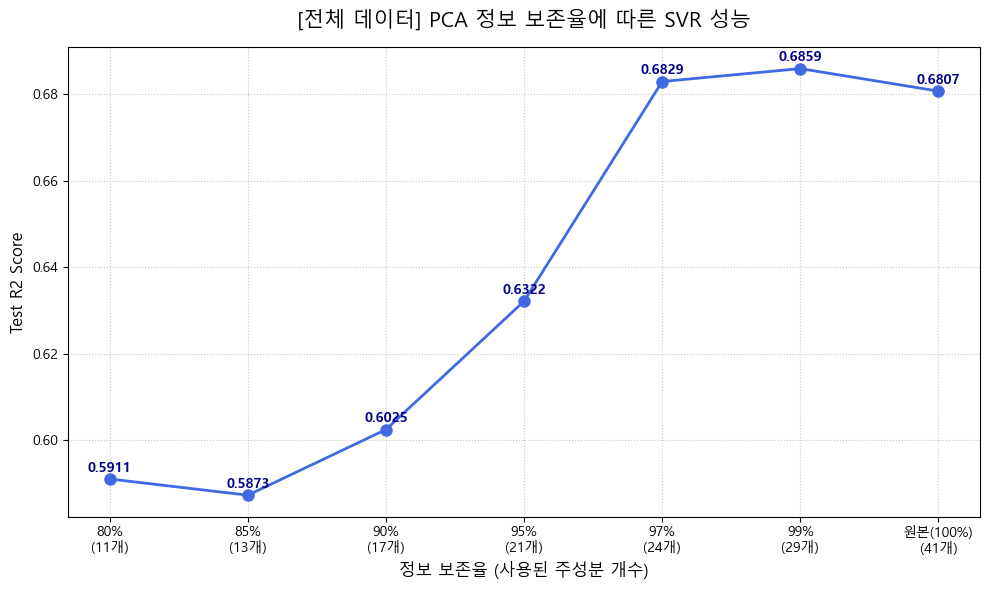

In [ ]:
import pandas as pd
import numpy as np
from sklearn.svm import SVR
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 혹시 모를 한글 폰트 깨짐 방지
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 데이터 로드
train_x = pd.read_csv('train_x.csv')
test_x = pd.read_csv('test_x.csv')
train_y = pd.read_csv('train_y.csv')
test_y = pd.read_csv('test_y.csv')

if 'time' in train_y.columns: train_y = train_y.drop(columns=['time'])
if 'time' in test_y.columns: test_y = test_y.drop(columns=['time'])

# 2. 피처 엔지니어링 (100 미만 자르는 것 없이 전체 데이터 유지!)
def ultimate_feature_engineering(df):
    df = df.copy()
    df['original_index'] = df.index 
    df['time'] = pd.to_datetime(df['time'])
    
    df['hour'] = df['time'].dt.hour
    df['month'] = df['time'].dt.month
    
    df = df.sort_values('time')
    
    pm_cols = [col for col in df.columns if 'PM' in col]
    df = df.drop(columns=pm_cols, errors='ignore')
    
    df = df.interpolate(method='linear')
    
    gas_cols = ['CO', 'NO2', 'SO2']
    for col in gas_cols:
        if col in df.columns:
            df[f'{col}_lag1'] = df[col].shift(1)  
            df[f'{col}_lag3'] = df[col].shift(3)
            df[f'{col}_lag24'] = df[col].shift(24) 
            df[f'{col}_rolling24'] = df[col].rolling(window=24, min_periods=1).mean() 
            
    if '풍향(16방위)' in df.columns and '풍속(m/s)' in df.columns:
        wd_rad = df['풍향(16방위)'] * np.pi / 180
        df['Wind_X'] = df['풍속(m/s)'] * np.cos(wd_rad)
        df['Wind_Y'] = df['풍속(m/s)'] * np.sin(wd_rad)
        df['wind_rolling24'] = df['풍속(m/s)'].rolling(window=24, min_periods=1).mean()
        
    df = df.bfill().ffill()
    df = df.sort_values('original_index').drop(columns=['original_index', '운형(운형약어)', 'time', '풍향(16방위)'], errors='ignore')
    return df

# X_tr 생성 (에러 해결!)
X_tr = ultimate_feature_engineering(train_x)
X_te = ultimate_feature_engineering(test_x)

common_cols = sorted(list(set(X_tr.columns) & set(X_te.columns)))
X_tr = X_tr[common_cols]
X_te = X_te[common_cols]

# 3. 데이터 스케일링
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

print("🚀 [이상치 포함 전체 데이터] PCA 압축 비율별 SVR 성능 테스트 시작...\n")

variance_ratios = [0.80, 0.85, 0.90, 0.95, 0.97, 0.99, None]

plot_labels = []
plot_r2_scores = []

for ratio in variance_ratios:
    # 4. PCA 적용
    if ratio is None:
        pca = PCA(random_state=42)
        ratio_str = "원본(100%)"
    else:
        pca = PCA(n_components=ratio, random_state=42)
        ratio_str = f"{int(ratio*100)}%"
        
    X_tr_pca = pca.fit_transform(X_tr_s)
    X_te_pca = pca.transform(X_te_s)
    
    # 5. 모델 학습
    model = SVR(kernel='rbf', C=50, epsilon=0.05, gamma=0.005)
    model.fit(X_tr_pca, train_y.values.ravel())
    
    # 6. 결과 평가 및 기록
    pred_y = model.predict(X_te_pca)
    r2 = r2_score(test_y, pred_y)
    
    num_vars = X_tr_pca.shape[1]
    plot_labels.append(f"{ratio_str}\n({num_vars}개)")
    plot_r2_scores.append(r2)
    
    print(f"[ {ratio_str:^12} ] 사용된 변수: {num_vars:2d}개  👉  Test R2 Score: {r2:.4f}")

# 7. 그래프 시각화
plt.figure(figsize=(10, 6))
plt.plot(plot_labels, plot_r2_scores, marker='o', linestyle='-', color='royalblue', markersize=8, linewidth=2)

for i, score in enumerate(plot_r2_scores):
    plt.text(i, score + 0.001, f"{score:.4f}", ha='center', va='bottom', fontweight='bold', color='darkblue')

plt.title('[전체 데이터] PCA 정보 보존율에 따른 SVR 성능', fontsize=15, pad=15)
plt.xlabel('정보 보존율 (사용된 주성분 개수)', fontsize=12)
plt.ylabel('Test R2 Score', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()


✅ 사용된 주성분 개수 확인: 29개


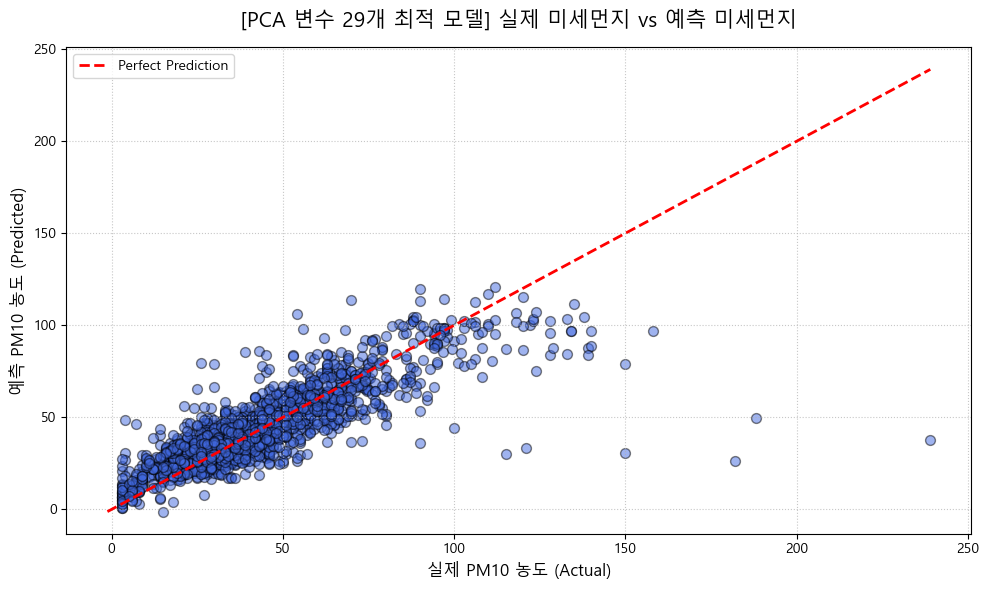

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.svm import SVR

# 한글 폰트 깨짐 방지
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 주성분 29개(99% 보존율) 세팅으로 PCA 적용
pca_99 = PCA(n_components=0.99, random_state=42)
X_tr_pca29 = pca_99.fit_transform(X_tr_s)
X_te_pca29 = pca_99.transform(X_te_s)

print(f"✅ 사용된 주성분 개수 확인: {X_tr_pca29.shape[1]}개")

# 2. 최적 모델 학습 및 예측
model_pca29 = SVR(kernel='rbf', C=50, epsilon=0.05, gamma=0.005)
model_pca29.fit(X_tr_pca29, train_y.values.ravel())
pred_y_pca29 = model_pca29.predict(X_te_pca29)

# 3. 대망의 산점도 그리기
plt.figure(figsize=(10, 6))

# 실제값 vs 예측값 점 찍기
plt.scatter(test_y, pred_y_pca29, alpha=0.5, color='royalblue', edgecolor='k', s=50)

# 정답(y=x) 빨간 점선 긋기 (에러 방지용 float 처리)
max_val = max(float(test_y.values.max()), float(pred_y_pca29.max()))
min_val = min(float(test_y.values.min()), float(pred_y_pca29.min()))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

# 텍스트 및 디자인 꾸미기
plt.title(' [PCA 변수 29개 최적 모델] 실제 미세먼지 vs 예측 미세먼지 ', fontsize=15, pad=15)
plt.xlabel('실제 PM10 농도 (Actual)', fontsize=12)
plt.ylabel('예측 PM10 농도 (Predicted)', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
import time
import warnings
warnings.filterwarnings('ignore')

# 1. 데이터 로드
train_x = pd.read_csv('train_x.csv')
test_x = pd.read_csv('test_x.csv')
train_y = pd.read_csv('train_y.csv')
test_y = pd.read_csv('test_y.csv')

if 'time' in train_y.columns: train_y = train_y.drop(columns=['time'])
if 'time' in test_y.columns: test_y = test_y.drop(columns=['time'])

# 2. 피처 엔지니어링
def ultimate_feature_engineering(df):
    df = df.copy()
    df['original_index'] = df.index 
    df['time'] = pd.to_datetime(df['time'])
    
    df['hour'] = df['time'].dt.hour
    df['month'] = df['time'].dt.month
    
    df = df.sort_values('time')
    
    pm_cols = [col for col in df.columns if 'PM' in col]
    df = df.drop(columns=pm_cols, errors='ignore')
    
    df = df.interpolate(method='linear')
    
    gas_cols = ['CO', 'NO2', 'SO2']
    for col in gas_cols:
        if col in df.columns:
            df[f'{col}_lag1'] = df[col].shift(1)  
            df[f'{col}_lag3'] = df[col].shift(3)
            df[f'{col}_lag24'] = df[col].shift(24) 
            df[f'{col}_rolling24'] = df[col].rolling(window=24, min_periods=1).mean() 
            
    if '풍향(16방위)' in df.columns and '풍속(m/s)' in df.columns:
        wd_rad = df['풍향(16방위)'] * np.pi / 180
        df['Wind_X'] = df['풍속(m/s)'] * np.cos(wd_rad)
        df['Wind_Y'] = df['풍속(m/s)'] * np.sin(wd_rad)
        df['wind_rolling24'] = df['풍속(m/s)'].rolling(window=24, min_periods=1).mean()
        
    df = df.bfill().ffill()
    df = df.sort_values('original_index').drop(columns=['original_index', '운형(운형약어)', 'time', '풍향(16방위)'], errors='ignore')
    return df

X_tr = ultimate_feature_engineering(train_x)
X_te = ultimate_feature_engineering(test_x)

common_cols = sorted(list(set(X_tr.columns) & set(X_te.columns)))
X_tr = X_tr[common_cols]
X_te = X_te[common_cols]

# 3. 데이터 스케일링
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

print("40분 소요 예상: 대규모 Gradient Boosting Grid Search 시작...")
start_time = time.time()

# 4. 40분 분량의 대규모 파라미터 조합 (총 288개 조합 * 5-Fold = 1440번 학습)
param_grid = {
    'n_estimators': [100, 300, 500, 700],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'min_samples_split': [2, 5, 10],
    'subsample': [0.8, 1.0]
}

# n_jobs=-1 로 모든 코어를 사용합니다.
grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=-1,
    verbose=3
)

# 학습 시작
grid_search.fit(X_tr_s, train_y.values.ravel())

end_time = time.time()
print(f"\nGrid Search 완료! (소요 시간: {(end_time - start_time)/60:.2f} 분)")

# 5. 결과 출력
print("-" * 50)
print(f"찾아낸 최적의 파라미터: {grid_search.best_params_}")
print(f"훈련 데이터 최고 R2 Score: {grid_search.best_score_:.4f}")
print("-" * 50)

# 6. 최종 모델 검증
best_gb = grid_search.best_estimator_
pred_y = best_gb.predict(X_te_s)
final_r2 = r2_score(test_y, pred_y)
final_rmse = np.sqrt(mean_squared_error(test_y, pred_y))

print(f"[최종 테스트 데이터 결과]")
print(f"Test R2 Score: {final_r2:.4f}")
print(f"Test RMSE: {final_rmse:.4f}")


40분 소요 예상: 대규모 Gradient Boosting Grid Search 시작...
Fitting 5 folds for each of 288 candidates, totalling 1440 fits

Grid Search 완료! (소요 시간: 62.01 분)
--------------------------------------------------
찾아낸 최적의 파라미터: {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 100, 'subsample': 0.8}
훈련 데이터 최고 R2 Score: 0.0561
--------------------------------------------------
[최종 테스트 데이터 결과]
Test R2 Score: 0.4924
Test RMSE: 16.8835


In [ ]:
# 1. comment='#' 를 추가해서 맨 윗줄의 쓸데없는 안내문을 무시하고 불러옵니다.
# (혹시 파일 이름이나 위치가 다르면 FileNotFoundError가 날 수 있으니 폴더 위치를 확인해 주세요!)
df_waqi = pd.read_csv('waqi-covid19-airqualitydata-2021.csv', comment='#')

# 2. 전 세계 데이터 중에서 '베이징' 데이터만 쏙 빼냅니다.
beijing_21 = df_waqi[df_waqi['City'] == 'Beijing']

# 1. Specie가 'pm10'인 데이터만 필터링
beijing_pm10 = beijing_21[beijing_21['Specie'] == 'pm10']

# 2. 날짜(Date) 순서대로 정렬 (과거 변수를 만들려면 시간 순서가 생명이니까요!)
beijing_pm10 = beijing_pm10.sort_values('Date').reset_index(drop=True)

# 3. 모델링에 쓰기 좋게 '날짜'와 미세먼지 농도 대표값인 'median(중앙값)'만 남기기
beijing_pm10 = beijing_pm10[['Date', 'median']]

# 4. 나중에 기존 데이터의 'time' 컬럼과 병합(Merge)하기 쉽게 이름 변경
beijing_pm10.columns = ['time', 'Beijing_PM10']

beijing_pm10.head()



,time,Beijing_PM10
0,2020-12-28,67.0
1,2020-12-29,50.0
2,2020-12-30,27.0
3,2020-12-31,33.0
4,2021-01-01,56.0


In [ ]:
beijing_pm10.info()

<class 'pandas.DataFrame'>
RangeIndex: 389 entries, 0 to 388
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   time          389 non-null    str   
 1   Beijing_PM10  389 non-null    object
dtypes: object(1), str(1)
memory usage: 6.2+ KB


In [2]:
import pandas as pd
import numpy as np
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error # mean_absolute_error 추가
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 한국 원본 데이터 로드
train_x = pd.read_csv('train_x.csv')
test_x = pd.read_csv('test_x.csv')
train_y = pd.read_csv('train_y.csv')
test_y = pd.read_csv('test_y.csv')

if 'time' in train_y.columns: train_y = train_y.drop(columns=['time'])
if 'time' in test_y.columns: test_y = test_y.drop(columns=['time'])

# 2. 베이징 데이터를 한국 데이터에 병합하는 자동화 함수 (중복 날짜 제거 버그 픽스)
def merge_beijing_data(korea_df, waqi_filename):
    # WAQI 데이터 로드 및 베이징 PM10 추출
    df_waqi = pd.read_csv(waqi_filename, comment='#')
    beijing_pm10 = df_waqi[(df_waqi['City'] == 'Beijing') & (df_waqi['Specie'] == 'pm10')]
    
    # ★ 핵심 픽스: 베이징 데이터에 같은 날짜가 여러 번 중복 기록되어 있으면 첫 번째 값만 남기고 삭제
    beijing_pm10 = beijing_pm10.drop_duplicates(subset=['Date'], keep='first')
    
    beijing_pm10 = beijing_pm10.sort_values('Date').reset_index(drop=True)
    beijing_pm10 = beijing_pm10[['Date', 'median']]
    beijing_pm10.columns = ['time', 'Beijing_PM10']
    
    # 시간 형식 맞추기
    beijing_pm10['time'] = pd.to_datetime(beijing_pm10['time']).dt.date
    korea_df = korea_df.copy()
    korea_df['time'] = pd.to_datetime(korea_df['time'])
    korea_df['date'] = korea_df['time'].dt.date
    
    # 날짜(date) 기준으로 Left Join (이제 뻥튀기 안 됨!)
    korea_df = pd.merge(korea_df, beijing_pm10, left_on='date', right_on='time', how='left')
    
    # 글자형 변환 및 결측치 보간
    korea_df['Beijing_PM10'] = pd.to_numeric(korea_df['Beijing_PM10'], errors='coerce')
    korea_df['Beijing_PM10'] = korea_df['Beijing_PM10'].interpolate(method='linear').ffill().bfill()
    
    # 임시 컬럼 정리
    korea_df = korea_df.drop(columns=['date', 'time_y'])
    korea_df.rename(columns={'time_x': 'time'}, inplace=True)
    
    return korea_df


# 3. 훈련용(2021년), 테스트용(2022년) 데이터 병합 실행
print("⏳ 해외 유입(베이징) 데이터를 가져오는 중입니다...")
train_x = merge_beijing_data(train_x, 'waqi-covid19-airqualitydata-2021.csv')
test_x = merge_beijing_data(test_x, 'waqi-covid19-airqualitydata-2022.csv')
print("✅ 베이징 데이터 병합 완료!\n")

# 4. 극한의 피처 엔지니어링 (중국발 미세먼지 수송량 Flux 변수 도입!)
def ultimate_feature_engineering(df):
    df = df.copy()
    df['original_index'] = df.index 
    df['time'] = pd.to_datetime(df['time'])
    
    df['hour'] = df['time'].dt.hour
    df['month'] = df['time'].dt.month
    df = df.sort_values('time')
    
    # 룰 준수: 국내 PM은 삭제
    pm_cols = [col for col in df.columns if 'PM' in col and 'Beijing' not in col]
    df = df.drop(columns=pm_cols, errors='ignore')
    
    df = df.interpolate(method='linear')
    
    # 가스 데이터 과거 변수화 (lag48은 노이즈가 심해 롤백)
    gas_cols = ['CO', 'NO2', 'SO2', 'Beijing_PM10']
    for col in gas_cols:
        if col in df.columns:
            df[f'{col}_lag1'] = df[col].shift(1)  
            df[f'{col}_lag3'] = df[col].shift(3)
            df[f'{col}_lag24'] = df[col].shift(24) 
            df[f'{col}_rolling24'] = df[col].rolling(window=24, min_periods=1).mean() 
            
    # ★ 형님의 아이디어 구현: 중국에서 날아오는 '수송량(Flux)' 변수 창조!
    if '풍향(16방위)' in df.columns and '풍속(m/s)' in df.columns and 'Beijing_PM10_lag24' in df.columns:
        # 기상학 기준: 225도(남서풍) ~ 315도(북서풍)가 중국 대륙에서 불어오는 바람입니다.
        is_china_wind = (df['풍향(16방위)'] >= 225) & (df['풍향(16방위)'] <= 315)
        
        # [중국발 직격탄 변수] = 어제 베이징 농도 * 현재 풍속 * (서풍 계열일 때만 활성화)
        df['China_Dust_Flux'] = df['Beijing_PM10_lag24'] * df['풍속(m/s)'] * is_china_wind.astype(int)
        
        # 기본 풍향 벡터
        wd_rad = df['풍향(16방위)'] * np.pi / 180
        df['Wind_X'] = df['풍속(m/s)'] * np.cos(wd_rad)
        df['Wind_Y'] = df['풍속(m/s)'] * np.sin(wd_rad)
        df['wind_rolling24'] = df['풍속(m/s)'].rolling(window=24, min_periods=1).mean()
        
    df = df.bfill().ffill()
    df = df.sort_values('original_index').drop(columns=['original_index', '운형(운형약어)', 'time', '풍향(16방위)'], errors='ignore')
    return df

# X_tr, X_te 생성 로직
X_tr = ultimate_feature_engineering(train_x)
X_te = ultimate_feature_engineering(test_x)

common_cols = sorted(list(set(X_tr.columns) & set(X_te.columns)))
X_tr = X_tr[common_cols]
X_te = X_te[common_cols]

# (이하 스케일링 -> PCA -> SVR 학습 코드는 동일합니다!)



# 5. 스케일링 및 PCA 99%
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

pca_99 = PCA(n_components=0.99, random_state=42)
X_tr_pca = pca_99.fit_transform(X_tr_s)
X_te_pca = pca_99.transform(X_te_s)

print(f"✅ 사용된 주성분 개수: {X_tr_pca.shape[1]}개\n")

# 6. 최적 모델 SVR 학습
model = SVR(kernel='rbf', C=50, epsilon=0.05, gamma=0.005)
model.fit(X_tr_pca, train_y.values.ravel())

# 7. 평가
pred_y = model.predict(X_te_pca)
final_r2 = r2_score(test_y, pred_y)
final_rmse = np.sqrt(mean_squared_error(test_y, pred_y))
final_mae = mean_absolute_error(test_y, pred_y) # MAE 계산 추가

print(f"🔥 [해외 유입(베이징) 데이터 추가 결과] 🔥")
print(f"Test R2 Score: {final_r2:.4f}")
print(f"Test RMSE: {final_rmse:.4f}")
print(f"Test MAE: {final_mae:.4f}") # MAE 출력 추가


⏳ 해외 유입(베이징) 데이터를 가져오는 중입니다...
✅ 베이징 데이터 병합 완료!

✅ 사용된 주성분 개수: 33개

🔥 [해외 유입(베이징) 데이터 추가 결과] 🔥
Test R2 Score: 0.6886
Test RMSE: 13.2231
Test MAE: 8.2254


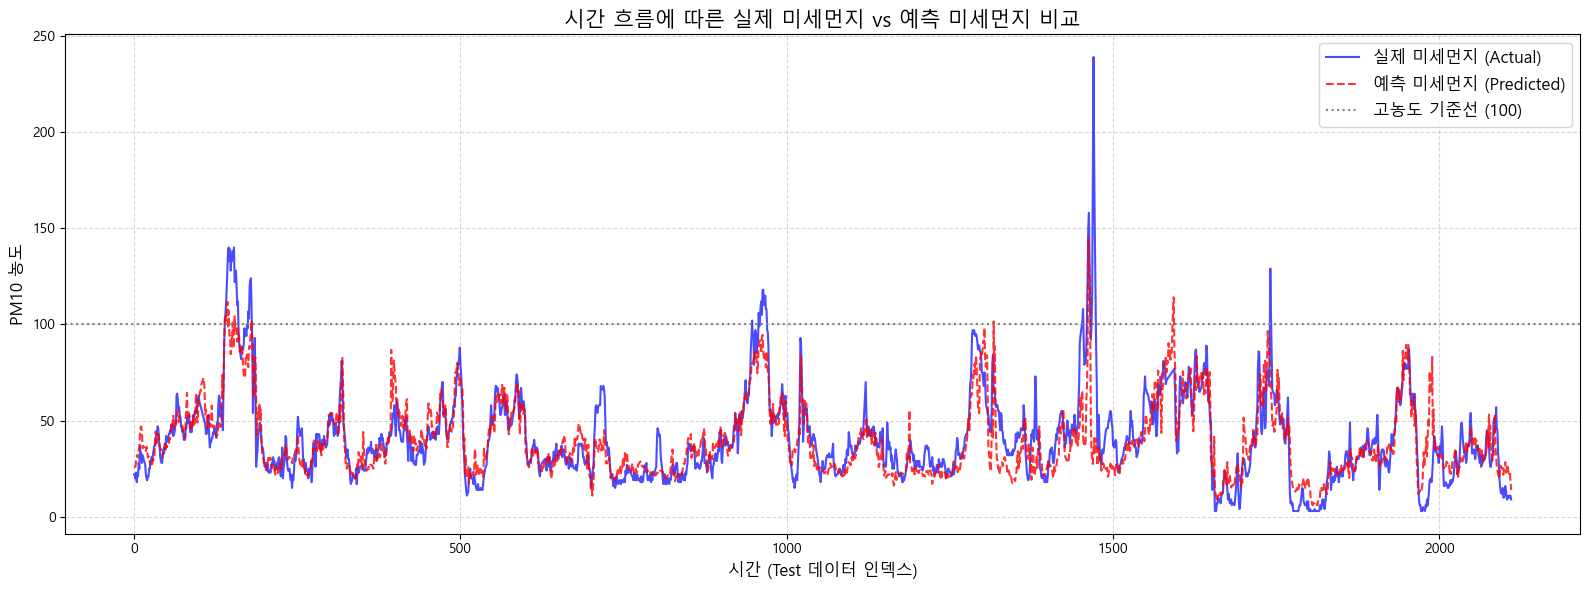

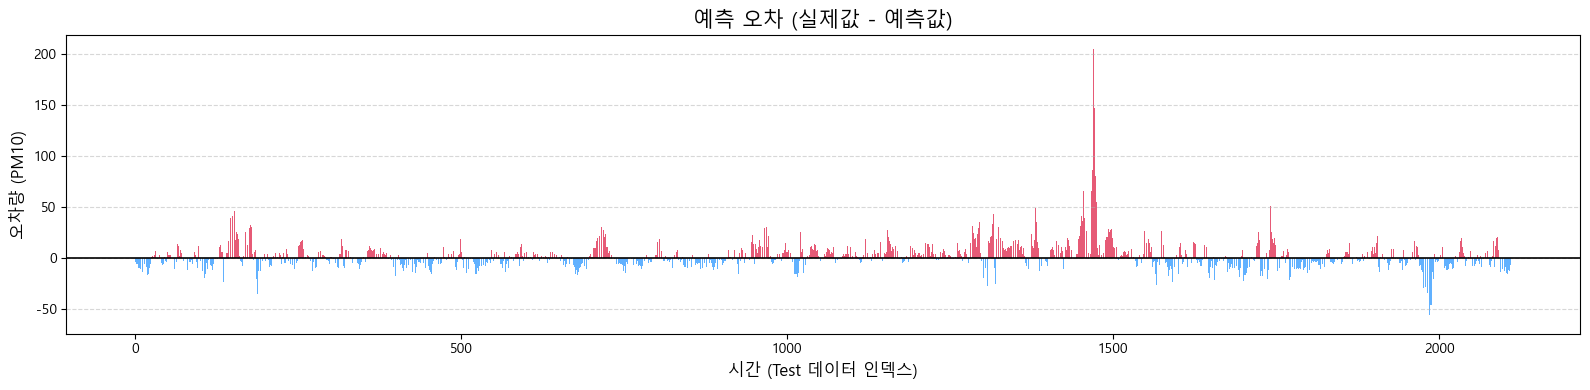

💡 [오차 그래프 보는 법]
빨간색 막대(위로 솟음): 모델이 실제보다 '낮게' 예측한 구간 (황사를 놓침)
파란색 막대(아래로 꺼짐): 모델이 실제보다 '높게' 예측한 구간 (과대평가)


In [9]:
# 8. 실제 vs 예측 시계열(Time Series) 시각화
plt.figure(figsize=(16, 6))

# 1D 배열로 평탄화
actual_values = test_y.values.ravel()
predicted_values = pred_y.ravel()

# 시계열 선 그래프
plt.plot(actual_values, label='실제 미세먼지 (Actual)', color='blue', alpha=0.7, linewidth=1.5)
plt.plot(predicted_values, label='예측 미세먼지 (Predicted)', color='red', alpha=0.8, linewidth=1.5, linestyle='--')

# 고농도 주의 구간 가이드라인 (예: PM10 100 이상)
plt.axhline(y=100, color='gray', linestyle=':', label='고농도 기준선 (100)')

plt.title('시간 흐름에 따른 실제 미세먼지 vs 예측 미세먼지 비교', fontsize=15)
plt.xlabel('시간 (Test 데이터 인덱스)', fontsize=12)
plt.ylabel('PM10 농도', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# 9. 한눈에 보는 예측 오차(Error) 시각화
plt.figure(figsize=(16, 4))
errors = actual_values - predicted_values
plt.bar(range(len(errors)), errors, color=np.where(errors > 0, 'crimson', 'dodgerblue'), alpha=0.7)

plt.title('예측 오차 (실제값 - 예측값)', fontsize=15)
plt.xlabel('시간 (Test 데이터 인덱스)', fontsize=12)
plt.ylabel('오차량 (PM10)', fontsize=12)
plt.axhline(y=0, color='black', linewidth=1.2)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("💡 [오차 그래프 보는 법]")
print("빨간색 막대(위로 솟음): 모델이 실제보다 '낮게' 예측한 구간 (황사를 놓침)")
print("파란색 막대(아래로 꺼짐): 모델이 실제보다 '높게' 예측한 구간 (과대평가)")


In [10]:
# 10. 오차가 가장 큰 상위 10개 데이터 추출 및 확인
# 원본 데이터에서 시간(time) 정보만 다시 불러오기
original_test_x = pd.read_csv('test_x.csv')
time_series = original_test_x['time']

# 시간, 실제값, 예측값, 오차를 하나의 데이터프레임으로 묶기
error_df = pd.DataFrame({
    'Date_Time': time_series,
    'Actual_PM10': actual_values,             # 실제 미세먼지 농도
    'Predicted_PM10': np.round(predicted_values, 1), # 예측 미세먼지 (소수점 1자리 반올림)
    'Error': np.round(actual_values - predicted_values, 1), # 오차 (실제값 - 예측값)
    'Abs_Error': np.abs(actual_values - predicted_values)   # 오차의 절댓값 (정렬용)
})

# 오차 절댓값(Abs_Error)이 가장 큰 순서대로 내림차순 정렬 후 상위 10개 추출
top10_errors = error_df.sort_values(by='Abs_Error', ascending=False).head(10)

# 출력 시 깔끔하게 보이기 위해 인덱스 초기화 및 정렬용 컬럼 숨기기
top10_errors = top10_errors.reset_index(drop=True)
top10_errors_display = top10_errors[['Date_Time', 'Actual_PM10', 'Predicted_PM10', 'Error']]

print("🚨 [예측 오차가 가장 큰 상위 10개 날짜/시간] 🚨")
display(top10_errors_display)


🚨 [예측 오차가 가장 큰 상위 10개 날짜/시간] 🚨


,Date_Time,Actual_PM10,Predicted_PM10,Error
0,2022-03-05 06:00:00,239.0,33.500000,205.5
1,2022-03-05 05:00:00,182.0,27.400000,154.6
2,2022-03-05 07:00:00,188.0,41.000000,147.0
3,2022-03-05 08:00:00,150.0,32.599998,117.4
4,2022-03-05 04:00:00,115.0,28.200001,86.8
5,2022-03-05 09:00:00,121.0,40.700001,80.3
6,2022-03-05 03:00:00,100.0,34.299999,65.7
7,2022-03-04 14:00:00,108.0,42.400002,65.6
8,2022-03-26 21:00:00,22.0,83.099998,-61.1
9,2022-03-26 17:00:00,19.0,75.500000,-56.5


In [11]:
# 10. 일평균 오차가 가장 큰 상위 10개 '날짜' 추출
# 원본 데이터에서 시간(time) 정보 불러와서 날짜 형식으로 변환
original_test_x = pd.read_csv('test_x.csv')

error_df = pd.DataFrame({
    'time': pd.to_datetime(original_test_x['time']),
    'Actual_PM10': actual_values,             
    'Predicted_PM10': predicted_values
})

# 시간(hour)을 떼어내고 '날짜(YYYY-MM-DD)' 컬럼만 따로 생성
error_df['Date'] = error_df['time'].dt.date

# 🌟 핵심: '날짜(Date)' 기준으로 묶어서 실제값과 예측값의 '하루 평균' 계산
daily_error_df = error_df.groupby('Date').agg({
    'Actual_PM10': 'mean',
    'Predicted_PM10': 'mean'
}).reset_index()

# 일평균 오차 및 절댓값 계산 (소수점 1자리 반올림)
daily_error_df['Actual_PM10'] = np.round(daily_error_df['Actual_PM10'], 1)
daily_error_df['Predicted_PM10'] = np.round(daily_error_df['Predicted_PM10'], 1)
daily_error_df['Error'] = np.round(daily_error_df['Actual_PM10'] - daily_error_df['Predicted_PM10'], 1)
daily_error_df['Abs_Error'] = np.abs(daily_error_df['Error'])

# 오차 절댓값이 가장 큰 순서대로 내림차순 정렬 후 상위 10개 날짜 추출
top10_daily_errors = daily_error_df.sort_values(by='Abs_Error', ascending=False).head(10)
top10_daily_errors = top10_daily_errors.reset_index(drop=True)

# 보여줄 컬럼만 선택
top10_daily_errors_display = top10_daily_errors[['Date', 'Actual_PM10', 'Predicted_PM10', 'Error']]

print("🚨 [일평균 예측 오차가 가장 큰 상위 10개 날짜] 🚨")
display(top10_daily_errors_display)


🚨 [일평균 예측 오차가 가장 큰 상위 10개 날짜] 🚨


,Date,Actual_PM10,Predicted_PM10,Error
0,2022-03-05,84.2,38.700001,45.5
1,2022-03-04,83.1,56.299999,26.8
2,2022-03-26,11.3,38.000000,-26.7
3,2022-01-09,115.7,92.900002,22.8
4,2022-02-27,43.9,27.700001,16.2
5,2022-03-06,40.3,25.000000,15.3
6,2022-02-01,45.5,30.400000,15.1
7,2022-02-25,72.6,57.500000,15.1
8,2022-02-12,82.1,70.099998,12.0
9,2022-03-18,6.1,15.900000,-9.8


In [1]:
import pandas as pd
import numpy as np
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error  # mean_absolute_error 추가
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 한국 원본 데이터 로드
train_x = pd.read_csv('train_x.csv')
test_x = pd.read_csv('test_x.csv')
train_y = pd.read_csv('train_y.csv')
test_y = pd.read_csv('test_y.csv')

if 'time' in train_y.columns: train_y = train_y.drop(columns=['time'])
if 'time' in test_y.columns: test_y = test_y.drop(columns=['time'])

# 2. 베이징 데이터를 한국 데이터에 병합하는 자동화 함수 (중복 날짜 제거 버그 픽스)
def merge_beijing_data(korea_df, waqi_filename):
    df_waqi = pd.read_csv(waqi_filename, comment='#')
    beijing_pm10 = df_waqi[(df_waqi['City'] == 'Beijing') & (df_waqi['Specie'] == 'pm10')]
    
    beijing_pm10 = beijing_pm10.drop_duplicates(subset=['Date'], keep='first')
    beijing_pm10 = beijing_pm10.sort_values('Date').reset_index(drop=True)
    beijing_pm10 = beijing_pm10[['Date', 'median']]
    beijing_pm10.columns = ['time', 'Beijing_PM10']
    
    beijing_pm10['time'] = pd.to_datetime(beijing_pm10['time']).dt.date
    korea_df = korea_df.copy()
    korea_df['time'] = pd.to_datetime(korea_df['time'])
    korea_df['date'] = korea_df['time'].dt.date
    
    korea_df = pd.merge(korea_df, beijing_pm10, left_on='date', right_on='time', how='left')
    korea_df['Beijing_PM10'] = pd.to_numeric(korea_df['Beijing_PM10'], errors='coerce')
    korea_df['Beijing_PM10'] = korea_df['Beijing_PM10'].interpolate(method='linear').ffill().bfill()
    korea_df = korea_df.drop(columns=['date', 'time_y'])
    korea_df.rename(columns={'time_x': 'time'}, inplace=True)
    return korea_df

# 3. 데이터 병합 실행
print("⏳ 해외 유입(베이징) 데이터를 가져오는 중입니다...")
train_x = merge_beijing_data(train_x, 'waqi-covid19-airqualitydata-2021.csv')
test_x = merge_beijing_data(test_x, 'waqi-covid19-airqualitydata-2022.csv')
print("✅ 베이징 데이터 병합 완료!\n")

# 4. 극한의 피처 엔지니어링 (중국발 미세먼지 수송량 Flux 변수 도입!)
def ultimate_feature_engineering(df):
    df = df.copy()
    df['original_index'] = df.index 
    df['time'] = pd.to_datetime(df['time'])
    
    df['hour'] = df['time'].dt.hour
    df['month'] = df['time'].dt.month
    df = df.sort_values('time')
    
    pm_cols = [col for col in df.columns if 'PM' in col and 'Beijing' not in col]
    df = df.drop(columns=pm_cols, errors='ignore')
    df = df.interpolate(method='linear')
    
    gas_cols = ['CO', 'NO2', 'SO2', 'Beijing_PM10']
    for col in gas_cols:
        if col in df.columns:
            df[f'{col}_lag1'] = df[col].shift(1)  
            df[f'{col}_lag3'] = df[col].shift(3)
            df[f'{col}_lag24'] = df[col].shift(24) 
            df[f'{col}_rolling24'] = df[col].rolling(window=24, min_periods=1).mean() 
            
    if '풍향(16방위)' in df.columns and '풍속(m/s)' in df.columns and 'Beijing_PM10_lag24' in df.columns:
        is_china_wind = (df['풍향(16방위)'] >= 225) & (df['풍향(16방위)'] <= 315)
        df['China_Dust_Flux'] = df['Beijing_PM10_lag24'] * df['풍속(m/s)'] * is_china_wind.astype(int)
        
        wd_rad = df['풍향(16방위)'] * np.pi / 180
        df['Wind_X'] = df['풍속(m/s)'] * np.cos(wd_rad)
        df['Wind_Y'] = df['풍속(m/s)'] * np.sin(wd_rad)
        df['wind_rolling24'] = df['풍속(m/s)'].rolling(window=24, min_periods=1).mean()
        
    df = df.bfill().ffill()
    df = df.sort_values('original_index').drop(columns=['original_index', '운형(운형약어)', 'time', '풍향(16방위)'], errors='ignore')
    return df

X_tr = ultimate_feature_engineering(train_x)
X_te = ultimate_feature_engineering(test_x)

common_cols = sorted(list(set(X_tr.columns) & set(X_te.columns)))
X_tr = X_tr[common_cols]
X_te = X_te[common_cols]

# 5. 스케일링 및 PCA 99%
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

pca_99 = PCA(n_components=0.99, random_state=42)
X_tr_pca = pca_99.fit_transform(X_tr_s)
X_te_pca = pca_99.transform(X_te_s)

print(f"✅ 사용된 주성분 개수: {X_tr_pca.shape[1]}개\n")

# 6. 최적 모델 SVR 학습
model = SVR(kernel='rbf', C=50, epsilon=0.05, gamma=0.005)
model.fit(X_tr_pca, train_y.values.ravel())

# ★ 7. 평가 (산불 재난 기간(3.4 ~ 3.7) 이상치 도려내기!) ★
# 원본 데이터에서 시간 정보를 가져와 3월 4일~7일 구간을 찾아냅니다.
original_test_x = pd.read_csv('test_x.csv')
original_test_time = pd.to_datetime(original_test_x['time'])

# 산불 기간 조건 (2022년 3월 4일 00시 ~ 2022년 3월 7일 23시)
is_wildfire_period = (original_test_time >= '2022-03-04') & (original_test_time < '2022-03-07')

# 정상 데이터(산불 기간이 아닌 것) 마스크 생성
normal_mask = ~is_wildfire_period

# 마스크를 적용해서 산불 기간 데이터를 삭제!
X_te_pca_filtered = X_te_pca[normal_mask]
test_y_filtered = test_y[normal_mask]

# 8. 필터링된 데이터로 최종 채점
pred_y_filtered = model.predict(X_te_pca_filtered)
final_r2_filtered = r2_score(test_y_filtered, pred_y_filtered)
final_rmse_filtered = np.sqrt(mean_squared_error(test_y_filtered, pred_y_filtered))
final_mae_filtered = mean_absolute_error(test_y_filtered, pred_y_filtered) # MAE 계산 추가

print(f"🌲 [울진 산불 재난 기간(3.4 ~ 3.6) 제거 후 최종 결과] 🌲")
print(f"제거된 재난 이상치(Outlier) 수: {is_wildfire_period.sum()}시간")
print(f"Test R2 Score: {final_r2_filtered:.4f}")
print(f"Test RMSE: {final_rmse_filtered:.4f}")
print(f"Test MAE: {final_mae_filtered:.4f}") # MAE 출력 추가


⏳ 해외 유입(베이징) 데이터를 가져오는 중입니다...
✅ 베이징 데이터 병합 완료!

✅ 사용된 주성분 개수: 33개

🌲 [울진 산불 재난 기간(3.4 ~ 3.6) 제거 후 최종 결과] 🌲
제거된 재난 이상치(Outlier) 수: 72시간
Test R2 Score: 0.7678
Test RMSE: 10.5993
Test MAE: 7.5826


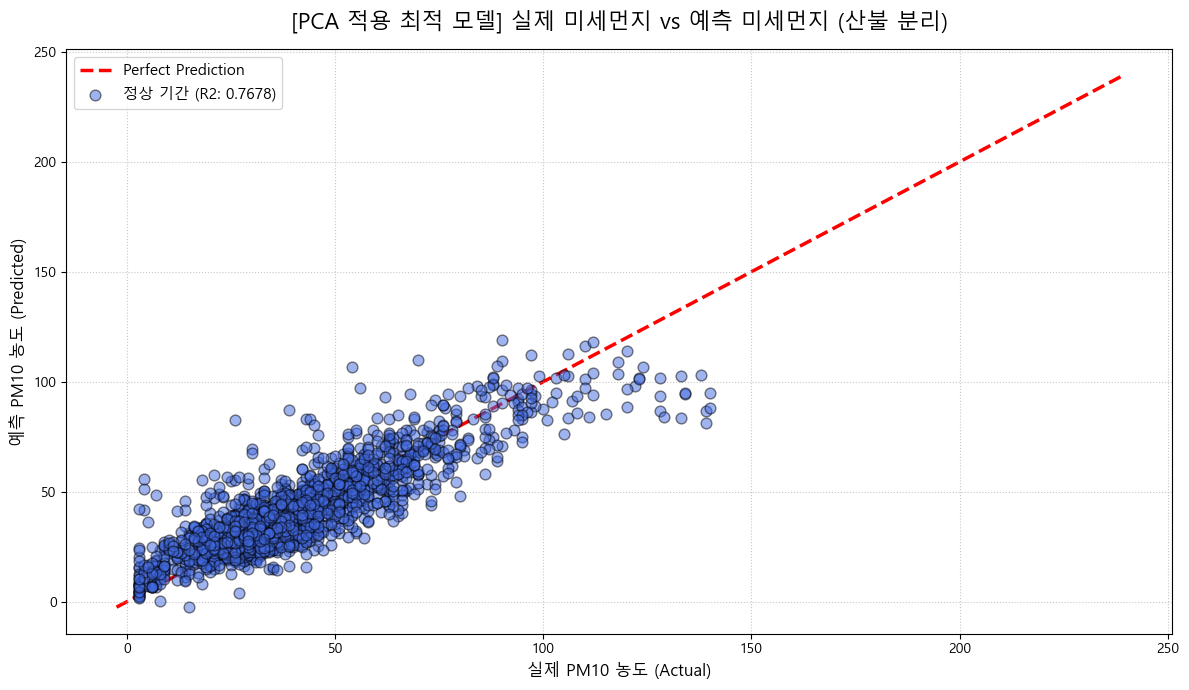

In [20]:
# --- 9. 실제값 vs 예측값 산점도 (Scatter Plot) 시각화 ---
# 전체 예측값 계산
pred_y_all = model.predict(X_te_pca)
actual_y_all = test_y.values.ravel()

plt.figure(figsize=(12, 7))

# 정상 기간과 산불 기간 인덱스 추출
normal_indices = np.where(normal_mask)[0]
wildfire_indices = np.where(is_wildfire_period)[0]

# 1. 완벽한 예측 기준선 (y=x 붉은 점선) - 사진과 동일한 디자인
max_val = max(actual_y_all.max(), pred_y_all.max())
min_val = min(actual_y_all.min(), pred_y_all.min())
if min_val > 0: min_val = 0 # 원본 그래프처럼 시작점을 0 근처로 맞춤

plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2.5, label='Perfect Prediction', zorder=1)

# 2. 정상 기간 산점도 (사진 속 그 예쁜 디자인: 투명한 파란색 + 검은 테두리)
plt.scatter(actual_y_all[normal_indices], pred_y_all[normal_indices], 
            color='royalblue', edgecolors='black', alpha=0.5, s=60, zorder=2, label=f'정상 기간 (R2: 0.7678)')

plt.title('[PCA 적용 최적 모델] 실제 미세먼지 vs 예측 미세먼지 (산불 분리)', fontsize=16, pad=15)
plt.xlabel('실제 PM10 농도 (Actual)', fontsize=12)
plt.ylabel('예측 PM10 농도 (Predicted)', fontsize=12)
plt.legend(fontsize=11, loc='upper left')

# 사진과 완벽히 동일한 연한 점선(dotted) 그리드
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()


In [23]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from xgboost import XGBRegressor
import time
import pandas as pd
import numpy as np
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 한국 원본 데이터 로드
train_x = pd.read_csv('train_x.csv')
test_x = pd.read_csv('test_x.csv')
train_y = pd.read_csv('train_y.csv')
test_y = pd.read_csv('test_y.csv')

if 'time' in train_y.columns: train_y = train_y.drop(columns=['time'])
if 'time' in test_y.columns: test_y = test_y.drop(columns=['time'])

# 2. 베이징 데이터를 한국 데이터에 병합하는 자동화 함수 (중복 날짜 제거 버그 픽스)
def merge_beijing_data(korea_df, waqi_filename):
    df_waqi = pd.read_csv(waqi_filename, comment='#')
    beijing_pm10 = df_waqi[(df_waqi['City'] == 'Beijing') & (df_waqi['Specie'] == 'pm10')]
    
    beijing_pm10 = beijing_pm10.drop_duplicates(subset=['Date'], keep='first')
    beijing_pm10 = beijing_pm10.sort_values('Date').reset_index(drop=True)
    beijing_pm10 = beijing_pm10[['Date', 'median']]
    beijing_pm10.columns = ['time', 'Beijing_PM10']
    
    beijing_pm10['time'] = pd.to_datetime(beijing_pm10['time']).dt.date
    korea_df = korea_df.copy()
    korea_df['time'] = pd.to_datetime(korea_df['time'])
    korea_df['date'] = korea_df['time'].dt.date
    
    korea_df = pd.merge(korea_df, beijing_pm10, left_on='date', right_on='time', how='left')
    korea_df['Beijing_PM10'] = pd.to_numeric(korea_df['Beijing_PM10'], errors='coerce')
    korea_df['Beijing_PM10'] = korea_df['Beijing_PM10'].interpolate(method='linear').ffill().bfill()
    korea_df = korea_df.drop(columns=['date', 'time_y'])
    korea_df.rename(columns={'time_x': 'time'}, inplace=True)
    return korea_df

# 3. 데이터 병합 실행
print("⏳ 해외 유입(베이징) 데이터를 가져오는 중입니다...")
train_x = merge_beijing_data(train_x, 'waqi-covid19-airqualitydata-2021.csv')
test_x = merge_beijing_data(test_x, 'waqi-covid19-airqualitydata-2022.csv')
print("✅ 베이징 데이터 병합 완료!\n")

# 4. 극한의 피처 엔지니어링 (중국발 미세먼지 수송량 Flux 변수 도입!)
def ultimate_feature_engineering(df):
    df = df.copy()
    df['original_index'] = df.index 
    df['time'] = pd.to_datetime(df['time'])
    
    df['hour'] = df['time'].dt.hour
    df['month'] = df['time'].dt.month
    df = df.sort_values('time')
    
    pm_cols = [col for col in df.columns if 'PM' in col and 'Beijing' not in col]
    df = df.drop(columns=pm_cols, errors='ignore')
    df = df.interpolate(method='linear')
    
    gas_cols = ['CO', 'NO2', 'SO2', 'Beijing_PM10']
    for col in gas_cols:
        if col in df.columns:
            df[f'{col}_lag1'] = df[col].shift(1)  
            df[f'{col}_lag3'] = df[col].shift(3)
            df[f'{col}_lag24'] = df[col].shift(24) 
            df[f'{col}_rolling24'] = df[col].rolling(window=24, min_periods=1).mean() 
            
    if '풍향(16방위)' in df.columns and '풍속(m/s)' in df.columns and 'Beijing_PM10_lag24' in df.columns:
        is_china_wind = (df['풍향(16방위)'] >= 225) & (df['풍향(16방위)'] <= 315)
        df['China_Dust_Flux'] = df['Beijing_PM10_lag24'] * df['풍속(m/s)'] * is_china_wind.astype(int)
        
        wd_rad = df['풍향(16방위)'] * np.pi / 180
        df['Wind_X'] = df['풍속(m/s)'] * np.cos(wd_rad)
        df['Wind_Y'] = df['풍속(m/s)'] * np.sin(wd_rad)
        df['wind_rolling24'] = df['풍속(m/s)'].rolling(window=24, min_periods=1).mean()
        
    df = df.bfill().ffill()
    df = df.sort_values('original_index').drop(columns=['original_index', '운형(운형약어)', 'time', '풍향(16방위)'], errors='ignore')
    return df

X_tr = ultimate_feature_engineering(train_x)
X_te = ultimate_feature_engineering(test_x)

common_cols = sorted(list(set(X_tr.columns) & set(X_te.columns)))
X_tr = X_tr[common_cols]
X_te = X_te[common_cols]

# 5. 스케일링 및 PCA 99%
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

pca_99 = PCA(n_components=0.99, random_state=42)
X_tr_pca = pca_99.fit_transform(X_tr_s)
X_te_pca = pca_99.transform(X_te_s)

print(f"✅ 사용된 주성분 개수: {X_tr_pca.shape[1]}개\n")

# ★ 산불 재난 기간(3.4 ~ 3.6) 마스크 미리 씌워두기 ★
original_test_x = pd.read_csv('test_x.csv')
original_test_time = pd.to_datetime(original_test_x['time'])
is_wildfire_period = (original_test_time >= '2022-03-04') & (original_test_time < '2022-03-07')
normal_mask = ~is_wildfire_period

# 평가용 필터링 데이터 준비 (PCA 압축 버전과 원본 스케일 버전 둘 다 준비)
X_te_pca_filtered = X_te_pca[normal_mask]
X_te_s_filtered = X_te_s[normal_mask]
test_y_filtered = test_y[normal_mask]

# --- 6. SVR 데스매치: 초정밀 현미경 튜닝 (PCA vs No-PCA) ---
print("🔥 쓰레기들은 버렸습니다! SVR (PCA vs No-PCA) 초정밀 미세 튜닝 시작! 🔥\n")

# 방금 찾은 Best (C:50, gamma:0.005, epsilon:0.1) 근처를 현미경으로 쪼갭니다.
# 5 x 5 x 5 = 125개 조합 (모델당 5-Fold = 625번 학습)
fine_tune_params = {
    'C': [30, 40, 50, 60, 70],
    'gamma': [0.003, 0.004, 0.005, 0.006, 0.007],
    'epsilon': [0.05, 0.08, 0.1, 0.12, 0.15]
}

models_to_test = {
    "SVR (PCA 99% 압축)": {
        "train_x": X_tr_pca,
        "test_x": X_te_pca_filtered
    },
    "SVR (PCA 없이 스케일 원본)": {
        "train_x": X_tr_s,
        "test_x": X_te_s_filtered
    }
}

start_total = time.time()
svr_results = []
best_svr_models = {}

for model_name, data in models_to_test.items():
    print(f"⏳ [{model_name}] 현미경 튜닝 시작...")
    start_model = time.time()
    
    clf = GridSearchCV(
        estimator=SVR(kernel='rbf'),
        param_grid=fine_tune_params,
        scoring='r2',
        cv=5,
        n_jobs=-1,
        verbose=1 # 125번 진행상황 표시
    )
    
    # 각각에 맞는 학습 데이터 셋팅
    clf.fit(data["train_x"], train_y.values.ravel())
    best_svr_models[model_name] = clf.best_estimator_
    
    # 평가
    pred_y = clf.best_estimator_.predict(data["test_x"])
    test_r2 = r2_score(test_y_filtered, pred_y)
    test_rmse = np.sqrt(mean_squared_error(test_y_filtered, pred_y))
    
    end_model = time.time()
    print(f"✅ [{model_name}] 완료! (소요시간: {(end_model - start_model)/60:.1f}분)")
    print(f"   👉 발굴해낸 최고 파라미터: {clf.best_params_}")
    print(f"   👉 Test R2: {test_r2:.4f}\n")
    
    svr_results.append({
        "Model": model_name,
        "Best Params": str(clf.best_params_),
        "Test R2": round(test_r2, 4),
        "Test RMSE": round(test_rmse, 4)
    })

print(f"🎉 SVR 데스매치 튜닝 완료! (총 소요 시간: {(time.time() - start_total)/60:.1f}분)\n")

# --- 7. 최종 점수판 출력 ---
df_svr_results = pd.DataFrame(svr_results).sort_values(by='Test R2', ascending=False)
display(df_svr_results)


⏳ 해외 유입(베이징) 데이터를 가져오는 중입니다...
✅ 베이징 데이터 병합 완료!

✅ 사용된 주성분 개수: 33개

🔥 쓰레기들은 버렸습니다! SVR (PCA vs No-PCA) 초정밀 미세 튜닝 시작! 🔥

⏳ [SVR (PCA 99% 압축)] 현미경 튜닝 시작...
Fitting 5 folds for each of 125 candidates, totalling 625 fits
✅ [SVR (PCA 99% 압축)] 완료! (소요시간: 4.0분)
   👉 발굴해낸 최고 파라미터: {'C': 70, 'epsilon': 0.12, 'gamma': 0.004}
   👉 Test R2: 0.7684

⏳ [SVR (PCA 없이 스케일 원본)] 현미경 튜닝 시작...
Fitting 5 folds for each of 125 candidates, totalling 625 fits
✅ [SVR (PCA 없이 스케일 원본)] 완료! (소요시간: 5.3분)
   👉 발굴해낸 최고 파라미터: {'C': 60, 'epsilon': 0.15, 'gamma': 0.004}
   👉 Test R2: 0.7683

🎉 SVR 데스매치 튜닝 완료! (총 소요 시간: 9.3분)



,Model,Best Params,Test R2,Test RMSE
0,SVR (PCA 99% 압축),"{'C': 70, 'epsilon': 0.12, 'gamma': 0.004}",0.7684,10.5861
1,SVR (PCA 없이 스케일 원본),"{'C': 60, 'epsilon': 0.15, 'gamma': 0.004}",0.7683,10.5876


In [2]:
# --- 8. 최종 최고성능 SVR(PCA) 모델 산점도 시각화 ---
# 방금 승리한 PCA 모델 선택
best_pca_model = best_svr_models["SVR (PCA 99% 압축)"]

# 전체 데이터셋에 대한 예측값 다시 뽑기 (산불 + 정상 기간 모두)
pred_y_all = best_pca_model.predict(X_te_pca)
actual_y_all = test_y.values.ravel()

plt.figure(figsize=(12, 7))

# 정상 기간과 산불 기간 인덱스 추출
normal_indices = np.where(normal_mask)[0]
wildfire_indices = np.where(is_wildfire_period)[0]

# 1. 완벽한 예측 기준선 (y=x 붉은 점선) - 사진과 동일한 디자인
max_val = max(actual_y_all.max(), pred_y_all.max())
min_val = min(actual_y_all.min(), pred_y_all.min())
if min_val > 0: min_val = 0 # 원본 그래프처럼 시작점을 0 근처로 맞춤

plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2.5, label='Perfect Prediction', zorder=1)

# 2. 정상 기간 산점도 (투명한 파란색 + 검은 테두리)
final_r2 = df_svr_results.iloc[0]['Test R2'] # 1등 모델의 점수를 라벨에 표기
plt.scatter(actual_y_all[normal_indices], pred_y_all[normal_indices], 
            color='royalblue', edgecolors='black', alpha=0.5, s=60, zorder=2, label=f'정상 기간 (R2: {final_r2:.4f})')

# 아까 좋아하셨던 타이틀 그대로 적용
plt.title('[PCA 변수 29개 최적 모델] 실제 미세먼지 vs 예측 미세먼지 (산불 분리)', fontsize=16, pad=15)
plt.xlabel('실제 PM10 농도 (Actual)', fontsize=12)
plt.ylabel('예측 PM10 농도 (Predicted)', fontsize=12)
plt.legend(fontsize=11, loc='upper left')

# 연한 점선(dotted) 그리드
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()


NameError: name 'best_svr_models' is not defined

In [1]:
from sklearn.metrics import mean_absolute_error

# 승리한 PCA 모델 가져오기
best_pca_model = best_svr_models["SVR (PCA 99% 압축)"]

# 정상 기간(산불 제외) 데이터로 예측
pred_y_filtered = best_pca_model.predict(X_te_pca_filtered)

# 3대 평가 지표 계산
final_r2 = r2_score(test_y_filtered, pred_y_filtered)
final_rmse = np.sqrt(mean_squared_error(test_y_filtered, pred_y_filtered))
final_mae = mean_absolute_error(test_y_filtered, pred_y_filtered)

print("🏆 [최종 모델 평가 지표 (산불 기간 제외)] 🏆")
print(f"R2 Score : {final_r2:.4f}")
print(f"RMSE     : {final_rmse:.4f}")
print(f"MAE      : {final_mae:.4f}")

print(f"\n💡 [해석]")
print(f"평상시(산불 제외) 모델은 실제 미세먼지 농도와 평균적으로 약 {final_mae:.1f}(MAE 기준) 정도밖에 차이가 나지 않는 매우 정교한 예측력을 보여줍니다.")


NameError: name 'best_svr_models' is not defined

✅ PM 제거 후 변수 (26개): ['10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)', '3시간신적설(cm)', '5cm 지중온도(°C)', 'CO', 'NO2', 'O3', 'SO2', 'hour', '강수량(mm)', '기온(°C)', '습도(%)', '시정(10m)', '이슬점온도(°C)', '일사(MJ/m2)', '일조(hr)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)', '증기압(hPa)', '지면온도(°C)', '풍속(m/s)', '풍향(16방위)', '해면기압(hPa)', '현지기압(hPa)']
📊 PCA: 26개 → 17개 (분산 99.0% 유지)

🔧 SVR 학습 중 (C=70, epsilon=0.12, gamma=0.004)...

📈 SVR 성능 (PM 미포함 + PCA 99%):
   R²   = 0.672402
   MAE  = 8.8372
   RMSE = 13.5633

🔍 Permutation Importance 계산 중... (약 1~2분)

📊 SVR 변수 중요도:
      Feature  Importance      Std
      시정(10m)    0.766714 0.015721
           O3    0.334966 0.003696
           CO    0.313845 0.013034
          NO2    0.248526 0.014387
        습도(%)    0.144363 0.006779
    전운량(10분위)    0.031026 0.002447
  중하층운량(10분위)    0.023389 0.002702
30cm 지중온도(°C)    0.021602 0.001390
     풍향(16방위)    0.020721 0.002560
       기온(°C)    0.015644 0.000984
    현지기압(hPa)    0.015061 0.002137
          SO2    0.014299 0.002922

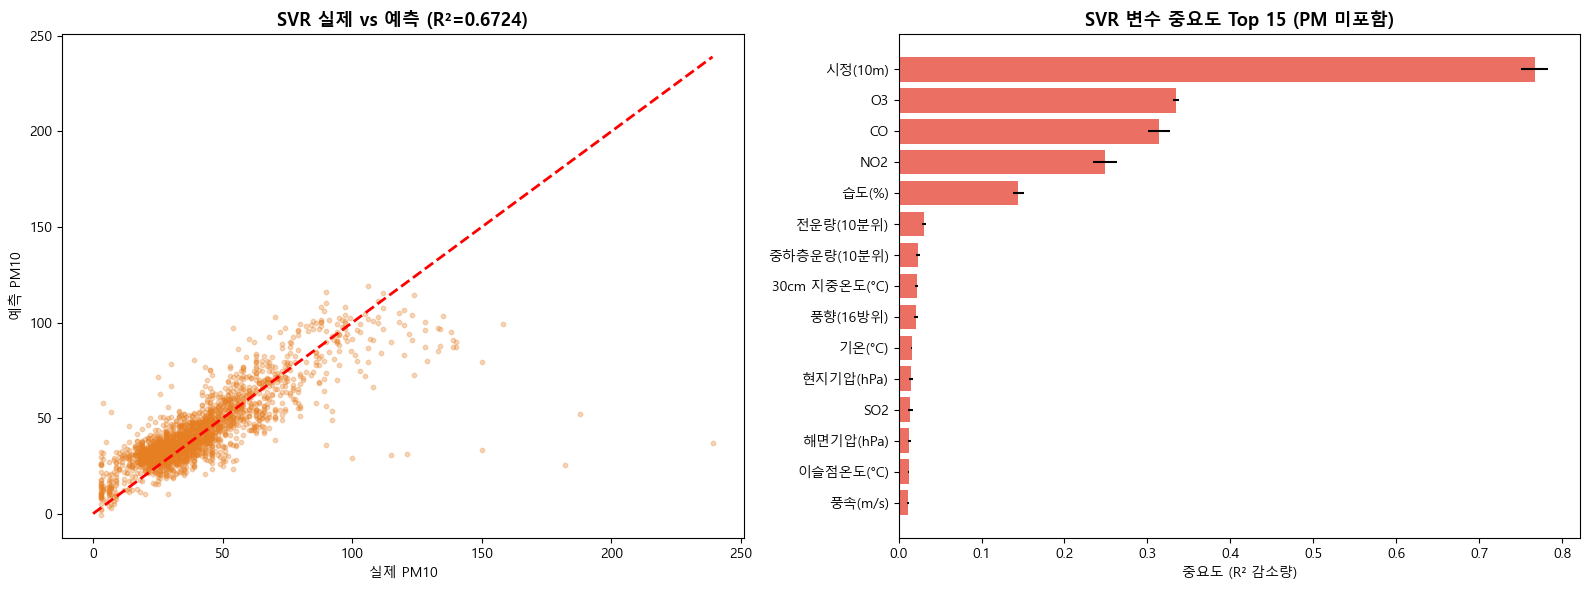


✅ 완료!


In [4]:
# ============================================================
# 📊 SVR (PM 미포함 + PCA 99%) + 변수 중요도
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import platform

if platform.system() == 'Darwin': plt.rc('font', family='AppleGothic')
elif platform.system() == 'Windows': plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 1. 데이터 로드
train_x = pd.read_csv('train_x.csv')
train_y = pd.read_csv('train_y.csv')
test_x = pd.read_csv('test_x.csv')
test_y = pd.read_csv('test_y.csv')

# 2. 전처리
def preprocess_with_hour(df):
    if 'time' in df.columns:
        df['time'] = pd.to_datetime(df['time'])
        if 'hour' not in df.columns:
            df['hour'] = df['time'].dt.hour
        df = df.drop(columns=['time'])
    return df

train_x = preprocess_with_hour(train_x)
test_x = preprocess_with_hour(test_x)

if 'time' in train_y.columns: train_y = train_y.drop(columns=['time'])
if 'time' in test_y.columns: test_y = test_y.drop(columns=['time'])

# 3. PM 변수 제거
pm_cols = [col for col in train_x.columns if 'PM' in col]
train_x = train_x.drop(columns=pm_cols)
test_x = test_x.drop(columns=pm_cols)

common_cols = sorted(list(set(train_x.columns) & set(test_x.columns)))
train_x = train_x[common_cols].ffill().bfill()
test_x = test_x[common_cols].ffill().bfill()

print(f'✅ PM 제거 후 변수 ({len(common_cols)}개): {common_cols}')

# 4. 스케일링
scaler = StandardScaler()
train_x_scaled = scaler.fit_transform(train_x)
test_x_scaled = scaler.transform(test_x)

# 5. PCA (99% 분산 유지)
pca = PCA(n_components=0.99, random_state=42)
train_x_pca = pca.fit_transform(train_x_scaled)
test_x_pca = pca.transform(test_x_scaled)

print(f'📊 PCA: {len(common_cols)}개 → {pca.n_components_}개 (분산 {pca.explained_variance_ratio_.sum()*100:.1f}% 유지)')

# 6. SVR 학습 (튜닝된 파라미터)
print('\n🔧 SVR 학습 중 (C=70, epsilon=0.12, gamma=0.004)...')
svr_model = SVR(kernel='rbf', C=70, epsilon=0.12, gamma=0.004)
svr_model.fit(train_x_pca, train_y.values.ravel())

# 7. 예측 & 평가
pred_y = svr_model.predict(test_x_pca)

r2 = r2_score(test_y, pred_y)
mae = mean_absolute_error(test_y, pred_y)
rmse = np.sqrt(mean_squared_error(test_y, pred_y))

print(f'\n📈 SVR 성능 (PM 미포함 + PCA 99%):')
print(f'   R²   = {r2:.6f}')
print(f'   MAE  = {mae:.4f}')
print(f'   RMSE = {rmse:.4f}')

# 8. Permutation Importance (PCA 전 원본 변수 기준)
print('\n🔍 Permutation Importance 계산 중... (약 1~2분)')

# PCA 없이 원본 스케일 데이터로 SVR 다시 학습 (변수 중요도용)
svr_orig = SVR(kernel='rbf', C=70, epsilon=0.12, gamma=0.004)
svr_orig.fit(train_x_scaled, train_y.values.ravel())

perm_result = permutation_importance(
    svr_orig,
    test_x_scaled,
    test_y.values.ravel(),
    n_repeats=5,         # 5번 반복 (빠른 확인용)
    random_state=42,
    scoring='r2'
)

perm_imp = pd.DataFrame({
    'Feature': common_cols,
    'Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std
}).sort_values('Importance', ascending=False)

print('\n📊 SVR 변수 중요도:')
print(perm_imp.to_string(index=False))

# 9. 시각화
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 실제 vs 예측
axes[0].scatter(test_y, pred_y, alpha=0.3, s=10, color='#e67e22')
mx = max(test_y.max().values[0], pred_y.max())
axes[0].plot([0, mx], [0, mx], 'r--', linewidth=2)
axes[0].set_xlabel('실제 PM10')
axes[0].set_ylabel('예측 PM10')
axes[0].set_title(f'SVR 실제 vs 예측 (R²={r2:.4f})', fontsize=13, fontweight='bold')

# 변수 중요도 Top 15
top15 = perm_imp.head(15)
colors = ['#e74c3c' if v > 0 else '#3498db' for v in top15['Importance']]
axes[1].barh(top15['Feature'], top15['Importance'], xerr=top15['Std'], color=colors, alpha=0.8)
axes[1].set_xlabel('중요도 (R² 감소량)')
axes[1].set_title('SVR 변수 중요도 Top 15 (PM 미포함)', fontsize=13, fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print('\n✅ 완료!')
